# Project: Gemini-powered LangGraph MoE with Backtracking

##  I. Project Overview
This project implements an advanced **Mixture of Experts (MoE)** architecture using **LangGraph** and **Google Gemini**. Unlike traditional static pipelines, this system dynamically orchestrates multiple specialized LLM agents (Experts) through an intelligent routing mechanism. By leveraging LangGraph's stateful, cyclic graph capabilities, the system ensures high-quality reasoning and robust problem-solving tailored to complex, multi-domain queries.

### Why "Backtracking" in the Naming?

The inclusion of **`backtracking`** in the project name, *Gemini_LangGraph_MoE_backtracking*, highlights the core algorithmic philosophy of this architecture: **Dynamic Error Correction and Path Readjustment**.

In standard MoE models, the router makes a one-shot decision to forward a query to an expert. However, if the selected expert generates an incorrect, incomplete, or hallucinated response, a sequential pipeline fails.

To overcome this limitation, this notebook implements a **Backtracking Feedback Loop** enabled by LangGraph's conditional edges and state management:

1. **State Evaluation:** After an Expert node generates an output, a Critic/Evaluator node assesses the quality and accuracy of the response.
2. **The Backtracking Mechanism:** If the response fails to meet the criteria, the workflow triggers a **backtrack**. Instead of proceeding forward, the graph's execution flow reverts to a previous state (the Router or a refinement node).
3. **Alternative Path Exploration:** The system dynamically adjusts its state, either re-routing the query to a different specialized expert or refining the prompt for a retry.

This iterative, self-correcting loop closely mirrors the classic computer science concept of **Backtracking Algorithms (e.g., DFS with pruning)**—exploring a path, detecting a dead end (poor LLM output), and returning to the last valid decision point to find the optimal solution.

---

## II. Key Architectural Components
* **Router:** Analyzes incoming user queries and dispatches them to the most competent expert.
* **Specialized Experts (MoE):** Distinct Gemini-powered agents optimized for specific tasks (e.g., mathematical reasoning, creative writing).
* **Evaluator (Critic):** Inspects the expert's output against pre-defined constraints.
* **Conditional Edges (The Loop):** The routing logic that either pushes the final answer to the user or forces a **backtrack** to correct the path.

---


## III. Environment Setup & Installation

Install the core libraries required for LangGraph orchestration and Gemini LLM integration.



In [1]:
!pip install langchain-core langchain-google-genai langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 6.5 MB/s  0:00:00
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [langchain-google-genai]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.


In [2]:
import os
from typing import TypedDict
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# Import LangChain Gemini integration and LangGraph orchestration core
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, END

In [3]:
# Google Gemini API Key
from google.colab import userdata
os.environ["GOOGLE_API_KEY"] = userdata.get('GeminiAPI')


## IV.  Model Initialization & Setup

In [6]:
# =====================================================================
# 1. Define the State Schema for the MoE workflow
# =====================================================================
class MoEState(TypedDict):
    question: str          # The original user query
    gpt_answer: str        # Output from Expert A (Powered by Gemini)
    claude_answer: str     # Output from Expert B (Powered by Gemini)
    is_consistent: bool    # Validation result (True if outputs align)
    feedback: str          # Feedback prompt for backtracking and retries
    retry_count: int       # Counter to track backtracking loops



In [7]:
# =====================================================================
# 2. Initialize Experts and Judges using Latest Free Gemini Models
# =====================================================================
# Migrated from older legacy models to state-of-the-art Gemini 3.x models.
expert_a = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0.7)  # Hyper-fast, cost-efficient model
expert_b = ChatGoogleGenerativeAI(model="gemini-3.6-flash", temperature=0.4)       # Highly capable flagship model
evaluator_llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0.0) # Deterministic model for consistency checks
judge_llm = ChatGoogleGenerativeAI(model="gemini-3.6-flash", temperature=0.2)      # Balanced model for final synthesis

## V. Define Agent Nodes & Workflow Functions

In [8]:
# =====================================================================
# 3. Define Agent Nodes & Workflow Functions
# =====================================================================

def generate_drafts_node(state: MoEState) -> dict:
    """Node for generating initial drafts from specialized experts."""
    question = state["question"]
    feedback = state.get("feedback", "")
    retry_count = state.get("retry_count", 0)

    prompt_content = "Question: {question}"
    if feedback:
        print(f"\n[Retry #{retry_count}] Regenerating responses based on evaluation feedback...")
        prompt_content += "\n\nCRITICAL FEEDBACK: The previous outputs showed a significant logical gap. Please refine your logic to bridge this gap based on the following instructions:\n{feedback}"
    else:
        print(f"\n[Attempt #1] Activating Expert Nodes.")

    prompt = ChatPromptTemplate.from_template(prompt_content)
    chain_a = prompt | expert_a | StrOutputParser()
    chain_b = prompt | expert_b | StrOutputParser()

    res_a = chain_a.invoke({"question": question, "feedback": feedback})
    res_b = chain_b.invoke({"question": question, "feedback": feedback})

    return {
        "gpt_answer": res_a,
        "claude_answer": res_b,
        "retry_count": retry_count + 1
    }

def verify_consistency_node(state: MoEState) -> dict:
    """Node for analyzing alignment and logical consistency between the experts."""
    print("[Verification Node] Evaluating response alignment and identifying logical gaps...")

    verify_prompt = ChatPromptTemplate.from_messages([
        ("system", "You are an advanced analyst tasked with evaluating whether two expert responses contain contradictory claims or severe logical gaps regarding the same query."),
        ("human", """Original Query: {question}

[Expert A's Response]
{gpt_answer}

[Expert B's Response]
{claude_answer}

Do these two responses contradict each other or contain critical blind spots that require alignment?
You must respond strictly in the following JSON format. Do not include any other explanatory text.
Note: Return pure raw text only without JSON code blocks (```json).

{{
    "is_consistent": true or false,
    "feedback": "If false, provide specific instructions on how both experts should complement each other to close the gap. If true, leave it as an empty string."
}}""")
    ])

    # Define the data structure for robust structured outputs
    class VerificationResult(TypedDict):
        is_consistent: bool
        feedback: str

    structured_evaluator = evaluator_llm.with_structured_output(VerificationResult)
    verify_chain = verify_prompt | structured_evaluator

    result = verify_chain.invoke({
        "question": state["question"],
        "gpt_answer": state["gpt_answer"],
        "claude_answer": state["claude_answer"]
    })

    return {
        "is_consistent": result["is_consistent"],
        "feedback": result["feedback"]
    }


def final_judge_node(state: MoEState) -> dict:
    """Node for synthesizing the aligned expert insights into a single master response."""
    print("[Final Judge Node] Synthesizing verified expert insights into a master response...")

    judge_prompt = ChatPromptTemplate.from_template("""Original Query: {question}

[Expert A's Verified Response]
{gpt_answer}

[Expert B's Verified Response]
{claude_answer}

Synthesize the brilliant insights from both experts into a highly comprehensive, well-structured, and readable 'Final Master Response'.""")

    judge_chain = judge_prompt | judge_llm | StrOutputParser()
    final_answer = judge_chain.invoke(state)

    return {"feedback": final_answer}


# =====================================================================
# 4. Define Conditional Routing Functions (The Backtracking Edge)
# =====================================================================
def route_after_verification(state: MoEState) -> str:
    """Determines whether to trigger a backtracking loop or proceed to final synthesis."""
    # Enforce a max retry limit to comply with free-tier Requests-Per-Minute (RPM) limits
    if state["retry_count"] >= 2:
        print("[Routing Edge] Maximum retry limit reached. Bypassing further loops.")
        return "proceed"

    if state["is_consistent"]:
        print("[Routing Edge] Consistency check passed! Moving forward to final synthesis.")
        return "proceed"
    else:
        print(f"[Routing Edge] Logical gap detected between expert responses. Triggering Backtracking Loop!")
        print(f"   [Reason/Feedback]: {state['feedback']}")
        return "retry"


In [9]:
# =====================================================================
# 5. Graph Construction & Compilation
# =====================================================================
workflow = StateGraph(MoEState)

# Add nodes to the workflow graph
workflow.add_node("generate_drafts", generate_drafts_node)
workflow.add_node("verify_consistency", verify_consistency_node)
workflow.add_node("final_judge", final_judge_node)

# Set the starting node of the workflow
workflow.set_entry_point("generate_drafts")
workflow.add_edge("generate_drafts", "verify_consistency")

# Define the backtracking loop logic via conditional routing
workflow.add_conditional_edges(
    "verify_consistency",
    route_after_verification,
    {
        "retry": "generate_drafts",
        "proceed": "final_judge"
    }
)

# Connect the final node to the end of the workflow
workflow.add_edge("final_judge", END)

# Compile the workflow into a runnable application
app = workflow.compile()


## VI. Graph Visualization

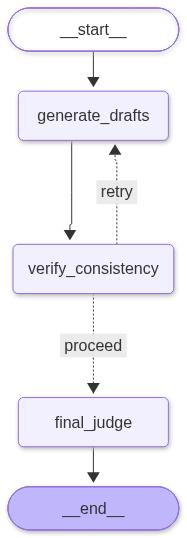

In [11]:
# =====================================================================
# 6. Workflow Graph Visualization
# =====================================================================
from IPython.display import Image, display

try:
    # Generate and display the architectural graph structure using Mermaid
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    # Fallback message if graphviz or required visualization prerequisites are missing
    print(f"Graph visualization failed: {e}")
    print("Please ensure pygraphviz or alternative visualization prerequisites are installed.")


## VII. Workflow Execution & Testing

In [12]:
# =====================================================================
# 7. Workflow Execution & Testing
# =====================================================================
if __name__ == "__main__":
    # Test query designed to deliberately trigger contradictions and test alignment/backtracking
    test_question = "Which came first, the chicken or the egg? Provide a response where conflicting scientific logic and evolutionary perspectives clash."

    print("--- Activating Free Gemini-Based Backtracking MoE ---")
    initial_state = {
        "question": test_question,
        "retry_count": 0,
        "feedback": ""
    }

    # Execute the compiled LangGraph workflow
    final_state = app.invoke(initial_state)

    print("\n==================== Final Synthesized Master Response ====================\n")
    print(final_state["feedback"])


--- Activating Free Gemini-Based Backtracking MoE ---

[Attempt #1] Activating Expert Nodes.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[Verification Node] Evaluating response alignment and identifying logical gaps...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[Routing Edge] Consistency check passed! Moving forward to final synthesis.
[Final Judge Node] Synthesizing verified expert insights into a master response...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



==================== Final Synthesized Master Response ====================

The age-old question of whether the chicken or the egg came first is far more than a linguistic paradox. It is a high-stakes collision between two distinct scientific disciplines: **Evolutionary Genetics** and **Molecular Biochemistry**. 

Depending on which scientific lens you look through, both sides possess rock-solid, empirically grounded logic to claim absolute victory—creating a fascinating scientific stalemate.

---

### Perspective 1: Evolutionary Biology & Paleontology
#### **The Verdict: The Egg Came First**

From the standpoint of deep time, population genetics, and evolutionary theory, the egg wins by a landslide.

*   **The Macro-Evolutionary Timeline:** Hard-shelled amniotic eggs—which allowed ancient tetrapods and reptiles to reproduce on dry land—first appeared in the fossil record approximately **340 million years ago**. Modern chickens (*Gallus gallus domesticus*) evolved relatively recently

## VIII. Architectural Analysis & Agent Expertise

The exceptional reasoning capability of this Mixture of Experts (MoE) system does not just come from the LangGraph loop, but from the deliberate diversification of agent profiles, inference behaviors, and mathematical settings (Temperature).

By pairing models with different cognitive weights and creativity thresholds, the architecture creates a powerful intellectual synergy.

### 1. Expert A (gemini-3.5-flash-lite | Temperature: 0.7)
*   **Specialization:** Creative Exploration, Divergent Thinking, and Intuitive Ideation.
*   **Rationale:** The `flash-lite` variant is inherently hyper-fast and lightweight. Combined with a higher temperature of `0.7`, this agent is optimized to think outside the box, generating diverse viewpoints, creative hypotheses, and unstructured brainstorming drafts without being overly constrained by rigid patterns.

### 2. Expert B (gemini-3.6-flash | Temperature: 0.4)
*   **Specialization:** Rigorous Logic, Fact-Based Deduction, and Deep Structural Analysis.
*   **Rationale:** As the flagship model in this tier, `gemini-3.6-flash` possesses a significantly larger cognitive capacity. Lowering its temperature to `0.4` reduces hallucinations and forces the agent to become deterministic, structured, and deeply analytical. It focuses on validating evidence, establishing scientific logic, and building airtight arguments.

---

## The Mechanics of the MoE Synergy

When a challenging query (such as the "Chicken or Egg" paradox) enters the system, these two experts inherently attack the problem from completely opposite dimensions:
*   **Expert A** quickly explores evolutionary anomalies, philosophical angles, or radical mutations.
*   **Expert B** constructs a precise, systematic analysis based on genetic mutation laws and protein synthesis boundaries.

The **Evaluator Node** then acts as the ultimate bridge. By detecting the logical gap between the high-creativity output (Expert A) and the high-logic output (Expert B), the system triggers the **Backtracking Loop**. This forces both experts to refine their answers iteratively until their reasoning aligns perfectly into a flawless, multifaceted **Master Response**.
